# Agente inversor: análisis exploratorio de los datos

Antes de entrenar al agente, revisamos los datos que va a ver: el precio diario
de GOOGL entre 2009-05-22 y 2018-08-29, el dataset común (`STOCKS_GOOGL` de
`gym-anytrading`), dividido en tres períodos consecutivos:

| Período | Fechas | Uso |
|---|---|---|
| train | 2009-05-22 → 2014-12-31 | entrenar al agente y ajustar la normalización |
| valid | 2015-01-01 → 2015-12-31 | elegir hiperparámetros |
| test | 2016-01-01 → 2018-08-29 | evaluación final, una sola vez |

1. **Evolución del precio**
2. **Distribución de los retornos**
3. **Volatilidad**
4. **Tendencias y caídas**
5. **Volumen**
6. **Indicadores del estado**
7. **Conclusiones para el estado y la recompensa**

**Regla para no filtrar información del futuro en el análisis:** los tres
períodos se muestran para describir los datos, pero todo cálculo que sirva para
*decidir* algo (qué indicadores usar, qué tan predictivos son, cómo
normalizarlos) se hace solo con el período de entrenamiento.

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats

from rl_games_sb import features, investor

df = investor.load()
close = df["close"]
ret = np.log(close).diff().dropna()  # retorno logarítmico diario
PERIODS = list(investor.SPLITS)
COLORS = {"train": "tab:blue", "valid": "tab:orange", "test": "tab:green"}


def shade_periods(ax):
    # Fondo de color para cada período.
    for p, (start, end) in investor.SPLITS.items():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=COLORS[p], alpha=0.08, label=p)


df.head()

,open,high,low,close,volume
timestamp,,,,,
2009-05-22,198.528534,199.524521,196.196198,196.946945,3433700
2009-05-26,196.171173,202.702698,195.195190,202.382385,6202700
2009-05-27,203.023026,206.136139,202.607605,202.982986,6062500
2009-05-28,204.544540,206.016022,202.507507,205.405411,5332200
2009-05-29,206.261261,208.823822,205.555557,208.823822,5291100


## 1. Evolución histórica del precio

La escala logarítmica hace que una misma distancia vertical sea el mismo
cambio porcentual, así que 2009 y 2018 se pueden comparar aunque el precio
sea seis veces mayor.

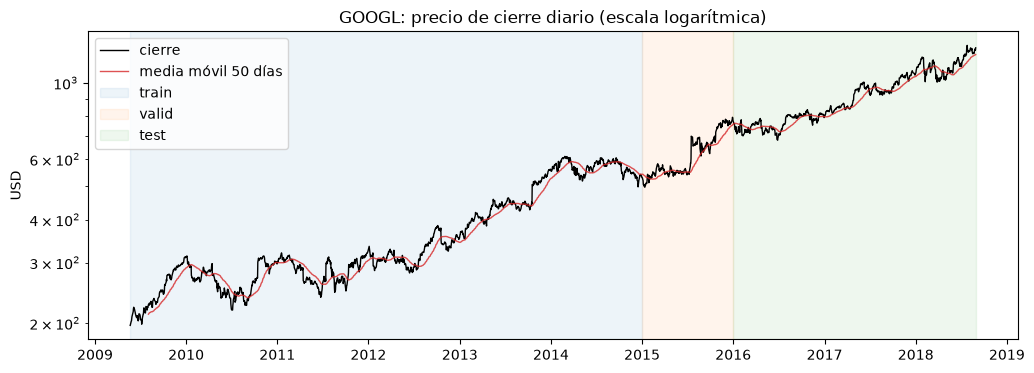

,inicio,fin,días,precio inicial,precio final,comprar y mantener,retorno anualizado
train,2009-05-22,2014-12-31,1413,197,531,+169.4%,+19.4%
valid,2015-01-02,2015-12-31,252,530,778,+46.9%,+47.1%
test,2016-01-04,2018-08-29,670,759,1265,+66.5%,+21.2%


In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(close, lw=1, color="black", label="cierre")
ax.plot(close.rolling(50).mean(), lw=1, color="tab:red", alpha=0.8, label="media móvil 50 días")
shade_periods(ax)
ax.set_yscale("log")
ax.set_title("GOOGL: precio de cierre diario (escala logarítmica)")
ax.set_ylabel("USD")
ax.legend(loc="upper left")
plt.show()


def period_summary(c):
    return {
        "inicio": c.index[0].date(),
        "fin": c.index[-1].date(),
        "días": len(c),
        "precio inicial": c.iloc[0],
        "precio final": c.iloc[-1],
        "comprar y mantener": c.iloc[-1] / c.iloc[0] - 1,
        "retorno anualizado": (c.iloc[-1] / c.iloc[0]) ** (252 / (len(c) - 1)) - 1,
    }


summary = pd.DataFrame({p: period_summary(investor.split(close, p)) for p in PERIODS}).T
summary.style.format({
    "precio inicial": "{:.0f}",
    "precio final": "{:.0f}",
    "comprar y mantener": "{:+.1%}",
    "retorno anualizado": "{:+.1%}",
})

**Lo que muestra:**

- El precio pasa de ~$197 a ~$1.265: se multiplica por 6,4 en nueve años.
- La tendencia es alcista en los tres períodos. Comprar y mantener gana
  +169 % en train, +47 % en valid y +67 % en test (entre 19 % y 47 % anual).
- Hay caídas fuertes dentro de esa tendencia, sobre todo en 2010, 2011 y entre
  2014 y 2015 (sección 4).

**Implicación:** comprar y mantener será un baseline muy difícil de superar en
retorno. Cada día fuera del mercado tiene un costo de oportunidad, porque en
promedio el precio sube. Donde el agente sí puede aportar es en reducir las
caídas, saliéndose antes de los períodos malos.

## 2. Distribución de los retornos

Usamos el retorno logarítmico diario, $r_t = \ln(P_t / P_{t-1})$, que es casi
igual al retorno porcentual en días normales y se puede sumar entre días.

In [3]:
def describe(x):
    return {
        "días": len(x),
        "media diaria": x.mean(),
        "volatilidad anual": x.std() * np.sqrt(252),
        "asimetría": stats.skew(x),
        "curtosis (exceso)": stats.kurtosis(x),
        "% días al alza": (x > 0).mean(),
        "peor día": x.min(),
        "mejor día": x.max(),
        "p-valor Jarque-Bera": stats.jarque_bera(x).pvalue,
    }


table = pd.DataFrame({p: describe(investor.split(ret, p)) for p in PERIODS}).T
table.style.format({
    "días": "{:.0f}",
    "media diaria": "{:+.4f}",
    "volatilidad anual": "{:.1%}",
    "asimetría": "{:+.2f}",
    "curtosis (exceso)": "{:.1f}",
    "% días al alza": "{:.1%}",
    "peor día": "{:+.1%}",
    "mejor día": "{:+.1%}",
    "p-valor Jarque-Bera": "{:.1e}",
})

,días,media diaria,volatilidad anual,asimetría,curtosis (exceso),% días al alza,peor día,mejor día,p-valor Jarque-Bera
train,1412,+0.0007,24.3%,+0.35,10.7,52.0%,-8.7%,+12.9%,0.0e+00
valid,252,+0.0015,28.1%,+2.60,20.1,52.8%,-5.4%,+15.1%,0.0e+00
test,670,+0.0007,20.2%,-0.69,2.7,53.7%,-5.6%,+4.2%,3.1e-57


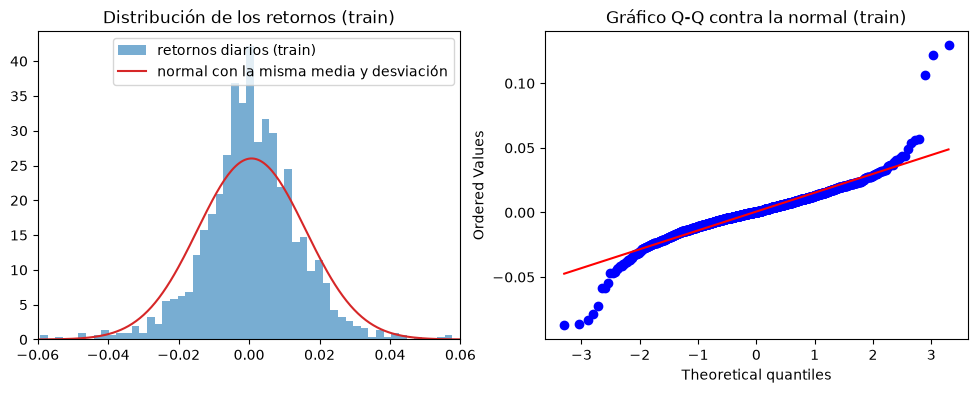

Los 5 movimientos diarios más grandes de toda la serie:
timestamp
2015-07-17  +15.1%
2013-10-18  +12.9%
2011-07-15  +12.2%
2010-10-15  +10.6%
 2012-01-20  -8.7%


In [4]:
train_ret = investor.split(ret, "train")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(train_ret, bins=100, density=True, alpha=0.6, label="retornos diarios (train)")
grid = np.linspace(train_ret.min(), train_ret.max(), 400)
ax1.plot(grid, stats.norm.pdf(grid, train_ret.mean(), train_ret.std()), color="tab:red",
         label="normal con la misma media y desviación")
ax1.set_xlim(-0.06, 0.06)
ax1.set_title("Distribución de los retornos (train)")
ax1.legend()

stats.probplot(train_ret, dist="norm", plot=ax2)
ax2.set_title("Gráfico Q-Q contra la normal (train)")
plt.show()

print("Los 5 movimientos diarios más grandes de toda la serie:")
print(ret.abs().nlargest(5).index.to_series().map(lambda d: f"{d.date()}  {ret[d]:+.1%}").to_string(index=False))

**Lo que muestra:**

- Los retornos **no son normales**: la prueba de Jarque-Bera rechaza la
  normalidad en los tres períodos (p ≈ 0). La curtosis en exceso es de 10,7 en
  train (una normal tiene 0): la mayoría de los días se mueven poco y unos pocos
  se mueven muchísimo (**colas gruesas**). En el gráfico Q-Q, los extremos se
  separan de la recta.
- Los movimientos más grandes (+10 % a +15 %) caen en días de publicación de
  resultados trimestrales, como 2015-07-17 o 2013-10-18. Son saltos que el
  precio de los días anteriores no anticipa.
- Valid es el período más extremo: un solo día (+15 %, julio 2015) le da
  curtosis de 20 y asimetría de +2,6.
- El precio sube un poco más de la mitad de los días (52–54 %). La ganancia de
  comprar y mantener viene de una ventaja pequeña y persistente, no de acertar
  muchos días.

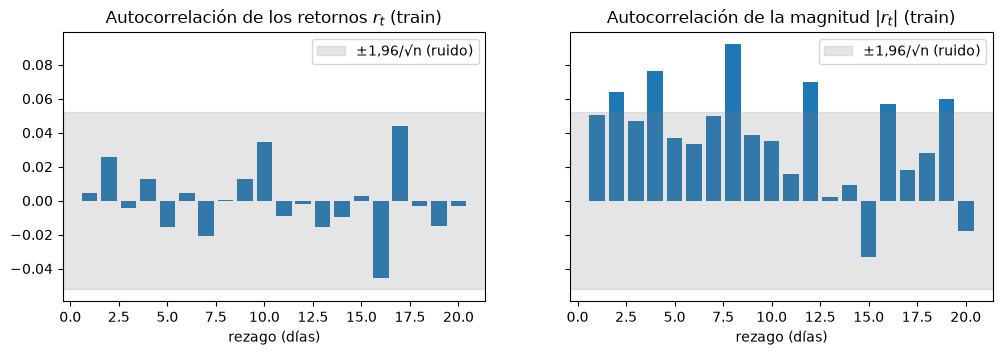

In [5]:
lags = np.arange(1, 21)
band = 1.96 / np.sqrt(len(train_ret))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, series, title in [
    (ax1, train_ret, "Autocorrelación de los retornos $r_t$"),
    (ax2, train_ret.abs(), "Autocorrelación de la magnitud $|r_t|$"),
]:
    ax.bar(lags, [series.autocorr(k) for k in lags], color="tab:blue")
    ax.axhspan(-band, band, color="gray", alpha=0.2, label="±1,96/√n (ruido)")
    ax.set_xlabel("rezago (días)")
    ax.set_title(title + " (train)")
    ax.legend()
plt.show()

**Lo que muestra:**

- El **signo** del retorno no tiene memoria: la autocorrelación de $r_t$ está
  dentro de la banda de ruido en casi todos los rezagos. Que hoy haya subido no
  dice si mañana sube.
- La **magnitud** sí tiene memoria: la autocorrelación de $|r_t|$ es positiva en
  la mayoría de los rezagos. Los días agitados vienen seguidos de días
  agitados (**agrupamiento de volatilidad**).

**Implicación:** predecir la dirección del precio será difícil para cualquier
agente. En cambio, el **riesgo** de los próximos días sí se puede estimar con el
pasado, y eso justifica incluir la volatilidad reciente en el estado.

## 3. Períodos de alta y baja volatilidad

Volatilidad móvil de 20 días hábiles (~1 mes), anualizada: $\sigma_{20} \cdot \sqrt{252}$.

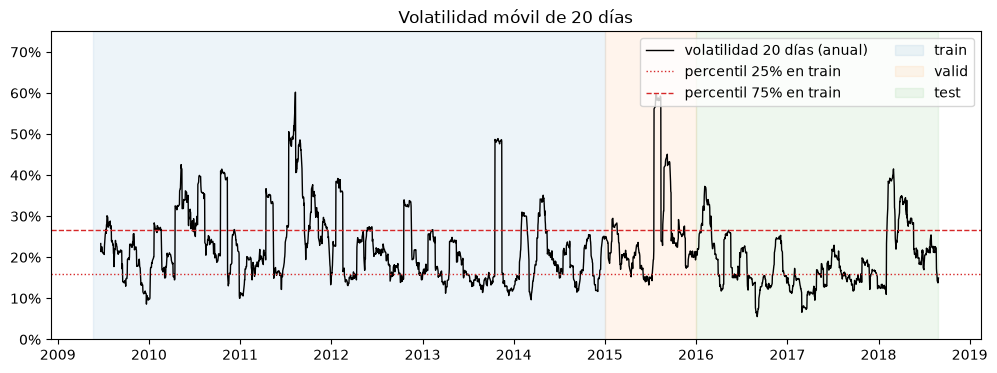

Meses más volátiles: 2011-08 (48%), 2015-08 (43%), 2011-07 (39%), 2015-09 (38%), 2015-07 (37%), 2010-05 (36%)
Meses más calmados:  2017-03 (9%), 2009-12 (11%), 2017-04 (12%), 2016-09 (12%), 2013-12 (12%), 2018-01 (13%)

       media mínimo máximo
train  22.7%   8.6%  60.2%
valid  25.9%  13.2%  59.7%
test   19.1%   5.5%  41.5%


In [6]:
vol = ret.rolling(20).std() * np.sqrt(252)
train_vol = investor.split(vol, "train")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(vol, lw=1, color="black", label="volatilidad 20 días (anual)")
for q, style in [(0.25, ":"), (0.75, "--")]:
    ax.axhline(train_vol.quantile(q), color="tab:red", ls=style, lw=1, label=f"percentil {q:.0%} en train")
shade_periods(ax)
ax.set_title("Volatilidad móvil de 20 días")
ax.set_ylim(0, 0.75)  # deja espacio para la leyenda
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="upper right", ncol=2)
plt.show()

monthly = vol.resample("ME").mean()
print("Meses más volátiles:", ", ".join(f"{d:%Y-%m} ({v:.0%})" for d, v in monthly.nlargest(6).items()))
print("Meses más calmados: ", ", ".join(f"{d:%Y-%m} ({v:.0%})" for d, v in monthly.nsmallest(6).items()))
print()
print(pd.DataFrame({p: investor.split(vol, p).agg(["mean", "min", "max"]) for p in PERIODS})
      .T.rename(columns={"mean": "media", "min": "mínimo", "max": "máximo"}).map("{:.1%}".format))

**Lo que muestra:**

- La volatilidad cambia mucho con el tiempo: va de ~6 % a ~60 % anual. No es
  un número fijo del activo, sino que pasa por **regímenes** de calma y de
  agitación que duran semanas o meses.
- Los meses más agitados coinciden con episodios conocidos: agosto de 2011
  (rebaja de la calificación de la deuda de EE. UU.), agosto de 2015
  (devaluación del yuan y desplome global), julio de 2015 y julio de 2011
  (resultados trimestrales) y mayo de 2010 (*flash crash*).
- Los tres períodos tienen niveles distintos: valid es el más agitado (media
  ~26 %) y test el más calmado (~19 %). Esto es un **cambio de distribución**:
  el agente se evaluará en un mercado más tranquilo que el de entrenamiento.

**Implicación:** con la misma posición, el riesgo de un día cambia según el
régimen. El indicador `vol_20` le permite al agente distinguir regímenes, por
ejemplo para reducir la exposición al 50 % cuando el mercado está agitado.

## 4. Tendencias y períodos de caída

El *drawdown* de cada día es cuánto está el precio por debajo de su máximo
anterior: $DD_t = P_t / \max_{s \le t} P_s - 1$.

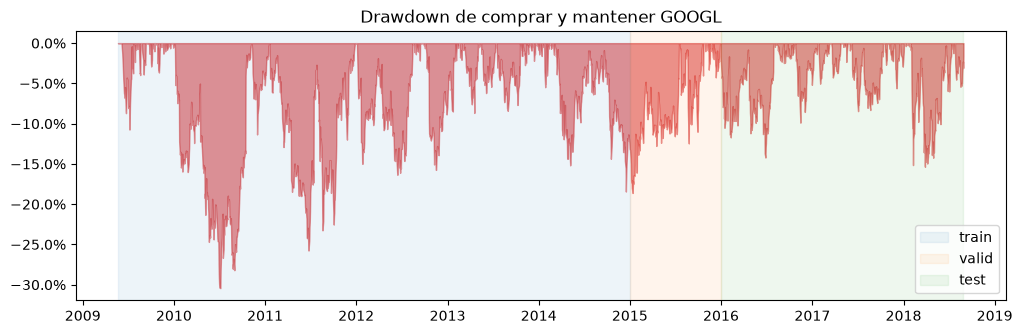

    máximo      fondo recuperación  caída  días hábiles bajo el máximo
2010-01-04 2010-07-06   2010-11-08 -30.4%                          214
2011-01-18 2011-06-24   2011-12-27 -25.8%                          238
2014-02-26 2015-01-12   2015-07-17 -18.6%                          350
2012-01-04 2012-06-14   2012-08-14 -16.3%                          154
2012-10-04 2012-11-16   2013-02-01 -15.7%                           80
2018-01-26 2018-03-28   2018-07-12 -15.4%                          115


In [7]:
drawdown = close / close.cummax() - 1

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(drawdown.index, drawdown, 0, color="tab:red", alpha=0.5)
shade_periods(ax)
ax.set_title("Drawdown de comprar y mantener GOOGL")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="lower right")
plt.show()


def drawdown_episodes(c, top=6):
    # Cada episodio va de un máximo hasta que el precio lo vuelve a superar.
    dd = c / c.cummax() - 1
    highs = dd.index[dd == 0]
    rows = []
    for _, seg in dd.groupby((dd == 0).cumsum()):
        if len(seg) == 1:
            continue
        later = highs[highs > seg.index[-1]]
        rows.append({
            "máximo": seg.index[0].date(),
            "fondo": seg.idxmin().date(),
            "recuperación": later[0].date() if len(later) else "sin recuperar",
            "caída": seg.min(),
            "días hábiles bajo el máximo": len(seg),
        })
    table = pd.DataFrame(rows).sort_values("caída").head(top)
    table["caída"] = table["caída"].map("{:.1%}".format)
    return table


print(drawdown_episodes(close).to_string(index=False))

In [8]:
sma50 = close.rolling(50).mean()
above_sma50 = (close > sma50)[sma50.notna()]  # sin los 49 días en que la media aún no existe


def trend_stats(p):
    c = investor.split(close, p)
    dd = c / c.cummax() - 1  # dentro de cada período, el máximo se cuenta desde su primer día
    return {
        "drawdown máximo": f"{dd.min():.1%}",
        "% días con caída > 10 %": f"{(dd < -0.10).mean():.0%}",
        "% días sobre la media de 50": f"{investor.split(above_sma50, p).mean():.0%}",
    }


print(pd.DataFrame({p: trend_stats(p) for p in PERIODS}).T)

# Solo train: ¿el retorno del día siguiente depende de estar sobre la media de 50?
train = investor.split(pd.DataFrame({"above": above_sma50, "next_ret": ret.shift(-1)}), "train").dropna()
train["above"] = train["above"].astype(bool)
print()
print("Retorno medio del día siguiente en train (puntos básicos):")
print(f"  precio sobre la media de 50 días: {train.next_ret[train.above].mean() * 1e4:+.1f} bps "
      f"({train.above.mean():.0%} de los días)")
print(f"  precio bajo la media de 50 días:  {train.next_ret[~train.above].mean() * 1e4:+.1f} bps")

      drawdown máximo % días con caída > 10 % % días sobre la media de 50
train          -30.4%                     32%                         59%
valid          -12.5%                      2%                         70%
test           -15.4%                      7%                         66%

Retorno medio del día siguiente en train (puntos básicos):
  precio sobre la media de 50 días: +9.4 bps (59% de los días)
  precio bajo la media de 50 días:  +1.7 bps


**Lo que muestra:**

- La peor caída es de **−30 %** (enero a julio de 2010), y el precio tardó
  10 meses en recuperar su máximo. La de 2011 fue de −26 %, y la de 2014–2015
  (−19 %) cruza de train a valid.
- En train, el precio estuvo más de un 10 % por debajo de su máximo en ~32 % de
  los días. Una estrategia que sea buena en retorno total puede ser muy
  incómoda de mantener.
- En train, el precio está sobre su media de 50 días el ~59 % del tiempo, y el
  día siguiente rinde más en promedio cuando lo está (+9 bps contra +2 bps).
  Es una señal de **tendencia** débil, y es la idea detrás de `gap_sma50`.

**Implicación:** como la actividad pide considerar el riesgo, la evaluación
debe reportar el drawdown máximo junto al retorno. Para la recompensa conviene
discutir si se penaliza el riesgo; si solo se premia el retorno, la deriva
alcista empuja al agente a estar siempre al 100 %.

## 5. Volumen

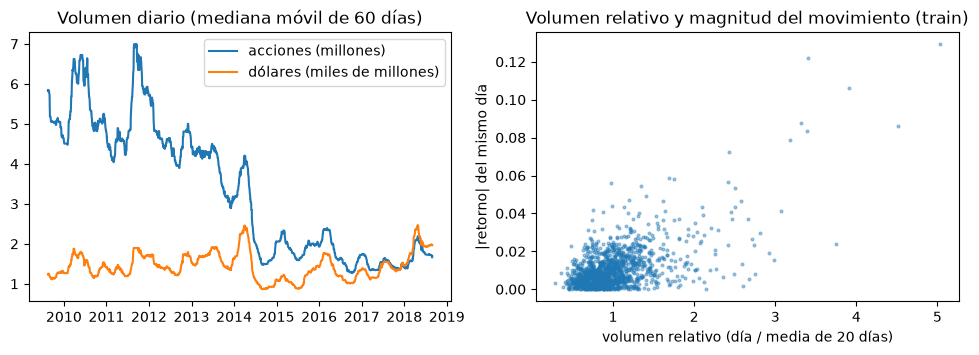

Correlación del volumen relativo del día t con... (train)
  |r| del mismo día t  Pearson +0.59 | Spearman +0.41
  |r| del día t+1      Pearson +0.20 | Spearman +0.12
  r del día t+1        Pearson +0.01 | Spearman +0.02


In [9]:
volume = df["volume"]
dollar_volume = close * volume
rel_volume = volume / volume.rolling(20).mean()  # volumen del día / su media de 20 días

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.plot(volume.rolling(60).median() / 1e6, label="acciones (millones)")
ax1.plot(dollar_volume.rolling(60).median() / 1e9, label="dólares (miles de millones)")
ax1.set_title("Volumen diario (mediana móvil de 60 días)")
ax1.legend()

train_days = investor.split(pd.DataFrame({"rel": rel_volume, "abs_ret": ret.abs()}), "train").dropna()
ax2.scatter(train_days.rel, train_days.abs_ret, s=4, alpha=0.4)
ax2.set_xlabel("volumen relativo (día / media de 20 días)")
ax2.set_ylabel("|retorno| del mismo día")
ax2.set_title("Volumen relativo y magnitud del movimiento (train)")
plt.show()

pairs = investor.split(pd.DataFrame({
    "rel": rel_volume,
    "abs_ret": ret.abs(),
    "next_abs_ret": ret.abs().shift(-1),
    "next_ret": ret.shift(-1),
}), "train").dropna()
print("Correlación del volumen relativo del día t con... (train)")
for col, label in [("abs_ret", "|r| del mismo día t"), ("next_abs_ret", "|r| del día t+1"), ("next_ret", "r del día t+1")]:
    print(f"  {label:<20} Pearson {pairs.rel.corr(pairs[col]):+.2f} | "
          f"Spearman {pairs.rel.corr(pairs[col], method='spearman'):+.2f}")

**Lo que muestra:**

- El volumen en **acciones** cae a la tercera parte (de ~5 millones diarios en
  2009 a ~1,5 millones en 2017), pero en **dólares** se mantiene estable,
  alrededor de 1.200–2.000 millones de dólares al día. La caída se explica por
  la subida del precio: hacen falta menos acciones para negociar los mismos
  dólares. Por eso el volumen absoluto no sirve como indicador: tiene una
  tendencia que no tiene nada que ver con el comportamiento futuro del precio.
- El **volumen relativo** (el del día dividido por su media de 20 días) sí
  está muy relacionado con la magnitud del movimiento **del mismo día**. Es
  esperable: los días de resultados se negocia mucho y el precio salta.
- Con la magnitud del **día siguiente** la relación es más débil (Spearman
  +0,12), parecida a la de los indicadores que ya están en el estado
  (sección 6). Con la **dirección** del día siguiente es prácticamente nula.

**Decisión:** por ahora el volumen no entra en el estado. El volumen absoluto
tiene una tendencia propia, y el relativo no anticipa la dirección y aporta
sobre el riesgo algo parecido a lo que ya aportan los indicadores de precio.
Queda como candidato (por ejemplo, el logaritmo del volumen relativo) si en
validación el agente necesitara más información de riesgo.

## 6. Comportamiento de los indicadores del estado

Los cinco indicadores de `features.py`, calculados solo con precios hasta el
día *t*:

| Indicador | Qué mide |
|---|---|
| `ret_1` | retorno logarítmico del último día |
| `ret_20` | retorno logarítmico de los últimos 20 días |
| `gap_sma50` | precio / media móvil de 50 días − 1 |
| `vol_20` | desviación estándar de los retornos diarios de 20 días |
| `rsi_14` | RSI de Wilder de 14 días, en [0, 1] |

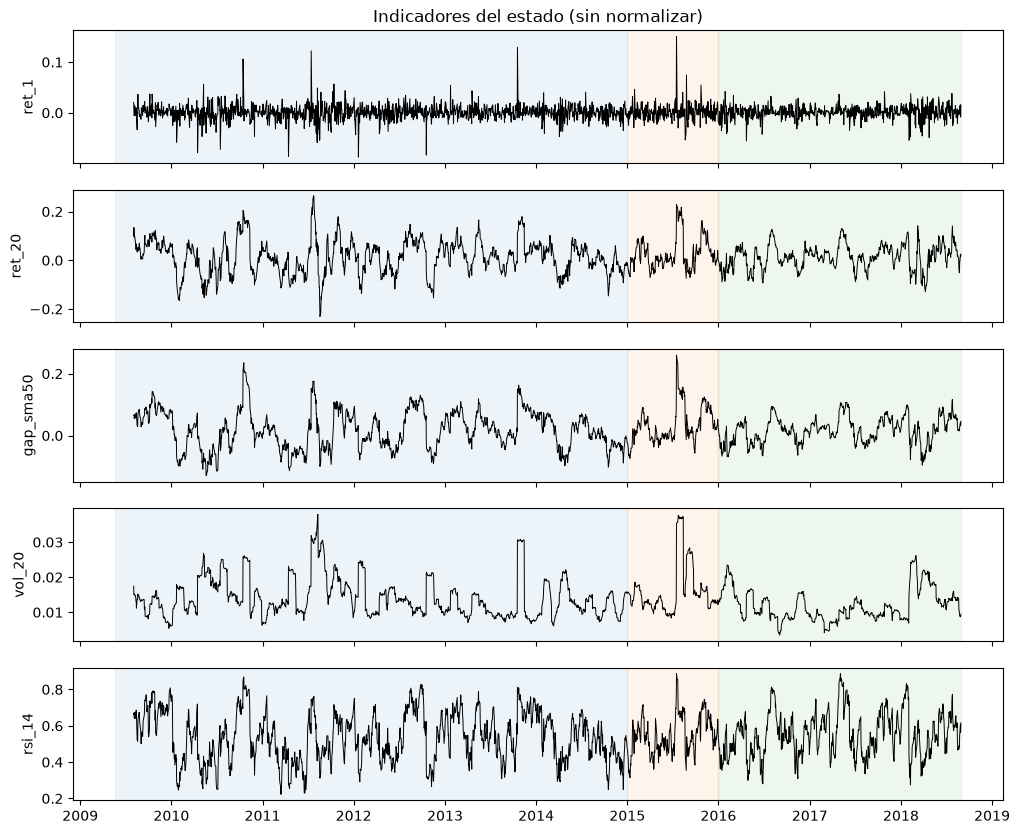

In [10]:
feats = features.compute(close)

fig, axes = plt.subplots(len(features.FEATURES), 1, figsize=(12, 10), sharex=True)
for ax, name in zip(axes, features.FEATURES):
    ax.plot(feats[name], lw=0.7, color="black")
    shade_periods(ax)
    ax.set_ylabel(name)
axes[0].set_title("Indicadores del estado (sin normalizar)")
plt.show()

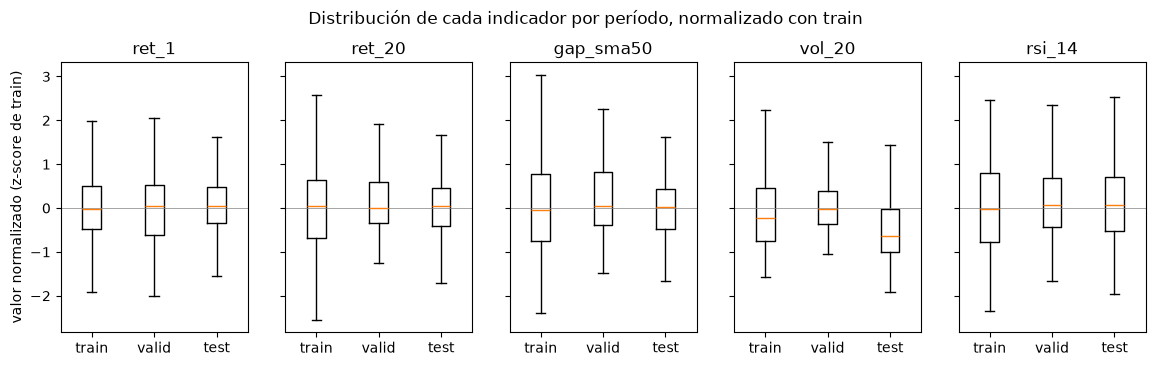

Media y desviación de los indicadores normalizados (train es 0 y 1 por construcción):
            ret_1  ret_20  gap_sma50  vol_20  rsi_14
train mean   0.00    0.00       0.00    0.00    0.00
      std    1.00    1.00       1.00    1.00    1.00
valid mean   0.06    0.24       0.30    0.36    0.11
      std    1.16    0.94       0.96    1.31    0.77
test  mean   0.01    0.01       0.00   -0.40    0.13
      std    0.83    0.70       0.67    0.80    0.89


In [11]:
# El normalizador se ajusta solo con train y se aplica igual a valid y test.
scaler = features.Scaler.fit(investor.split(feats, "train"))
scaled = scaler.transform(feats)

fig, axes = plt.subplots(1, len(features.FEATURES), figsize=(14, 3.5), sharey=True)
for ax, name in zip(axes, features.FEATURES):
    ax.boxplot([investor.split(scaled[name], p) for p in PERIODS], showfliers=False)
    ax.set_xticks(range(1, len(PERIODS) + 1), PERIODS)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_title(name)
axes[0].set_ylabel("valor normalizado (z-score de train)")
fig.suptitle("Distribución de cada indicador por período, normalizado con train", y=1.03)
plt.show()

print("Media y desviación de los indicadores normalizados (train es 0 y 1 por construcción):")
print(pd.concat({p: investor.split(scaled, p).agg(["mean", "std"]) for p in PERIODS}).round(2))

**Lo que muestra:**

- Los indicadores **no dependen de la escala del precio**: aunque el precio se
  multiplica por 6, `ret_1`, `ret_20` y `gap_sma50` oscilan alrededor de cero
  en todo el período y el RSI alrededor de 0,5. Por eso el mismo agente puede
  usarse en 2010 y en 2017.
- Con la normalización ajustada en train, valid y test quedan en rangos
  parecidos (medias entre −0,4 y +0,4 desviaciones). La mayor diferencia está
  en `vol_20`: valid es más volátil que train y test bastante menos, el mismo
  cambio de régimen de la sección 3.

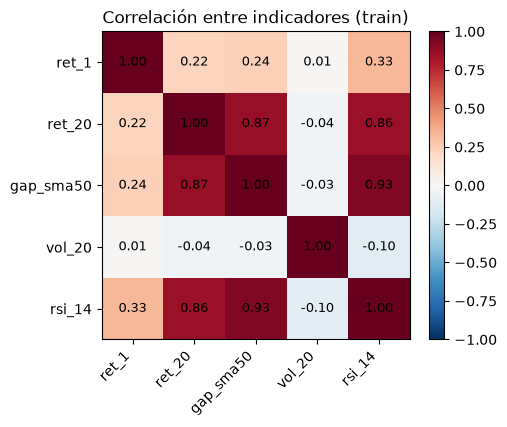

In [12]:
train_feats = investor.split(feats, "train")

fig, ax = plt.subplots(figsize=(5, 4))
corr = train_feats.corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im)
ax.set_title("Correlación entre indicadores (train)")
plt.show()

`ret_20`, `gap_sma50` y `rsi_14` están muy correlacionados entre sí, porque los
tres miden, de distinta forma, cuánto ha subido el precio en las últimas
semanas. `ret_1` y `vol_20` aportan información distinta.

Por último, la pregunta clave para el agente: **¿los indicadores de hoy dicen
algo sobre el retorno de mañana?** Se separan los días de train en cinco grupos
(quintiles) según el valor del indicador, y se mide en cada grupo el retorno
medio del día siguiente (dirección) y su magnitud media (riesgo).

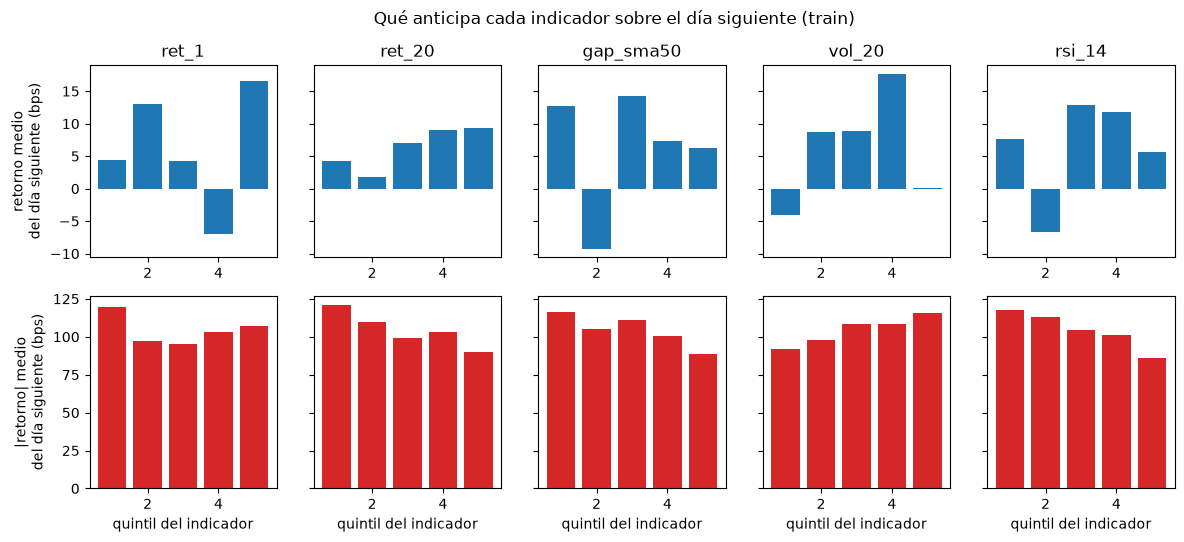

Correlación de Spearman en train:
           corr. con r(t+1)  corr. con |r(t+1)|
indicador                                      
ret_1                 0.032              -0.022
ret_20                0.005              -0.134
gap_sma50            -0.004              -0.125
vol_20                0.016               0.068
rsi_14                0.002              -0.144


In [13]:
train_next = investor.split(pd.DataFrame({"next_ret": ret.shift(-1)}).reindex(feats.index), "train").next_ret

fig, axes = plt.subplots(2, len(features.FEATURES), figsize=(14, 5.5), sharey="row")
rows = []
for k, name in enumerate(features.FEATURES):
    quintile = pd.qcut(train_feats[name], 5, labels=[1, 2, 3, 4, 5])
    by_q = train_next.groupby(quintile, observed=True)
    axes[0, k].bar(range(1, 6), by_q.mean() * 1e4, color="tab:blue")
    axes[1, k].bar(range(1, 6), by_q.apply(lambda x: x.abs().mean()) * 1e4, color="tab:red")
    axes[0, k].set_title(name)
    axes[1, k].set_xlabel("quintil del indicador")
    rows.append({
        "indicador": name,
        "corr. con r(t+1)": train_feats[name].corr(train_next, method="spearman"),
        "corr. con |r(t+1)|": train_feats[name].corr(train_next.abs(), method="spearman"),
    })
axes[0, 0].set_ylabel("retorno medio\ndel día siguiente (bps)")
axes[1, 0].set_ylabel("|retorno| medio\ndel día siguiente (bps)")
fig.suptitle("Qué anticipa cada indicador sobre el día siguiente (train)")
plt.show()

print("Correlación de Spearman en train:")
print(pd.DataFrame(rows).set_index("indicador").round(3))

**Lo que muestra:**

- **Dirección (fila superior):** ningún indicador ordena el retorno del día
  siguiente. Las barras suben y bajan sin patrón y las correlaciones están
  cerca de 0. Esto es lo esperable en un activo muy negociado: si un indicador
  tan simple anticipara la dirección, otros ya lo habrían aprovechado.
- **Riesgo (fila inferior):** aquí sí hay patrones claros. Cuando `vol_20` es
  alta, el movimiento del día siguiente es mayor. Cuando `ret_20`,
  `gap_sma50` o `rsi_14` son altos (el precio viene subiendo), el día
  siguiente tiende a ser más tranquilo, y las caídas recientes anticipan días
  agitados.

Ojo: estas correlaciones solo miran relaciones de un indicador a la vez y de
un día al siguiente. El agente puede combinar indicadores, y lo que importa es
el retorno acumulado mientras mantiene una posición, no el de un solo día.

## 7. Conclusiones para el estado y la recompensa

| Hallazgo | Evidencia | Decisión |
|---|---|---|
| Fuerte tendencia alcista en los tres períodos | comprar y mantener: +169 % / +47 % / +67 % | comprar y mantener es el baseline principal; la ventaja posible del agente está en el **riesgo** más que en el retorno |
| Retornos no normales, con colas gruesas | curtosis en exceso de 10,7 en train; Jarque-Bera p ≈ 0 | evaluar con drawdown y no solo con media y desviación; esperar choques que el estado no puede anticipar (días de resultados) |
| El signo del retorno no tiene memoria | autocorrelación de $r_t$ dentro de la banda de ruido; correlaciones de los indicadores con $r_{t+1}$ ≈ 0 | esperar una señal de dirección débil; un resultado negativo frente a comprar y mantener es plausible |
| La volatilidad se agrupa y cambia de régimen | autocorrelación de $|r_t|$ positiva; volatilidad de 6 % a 60 % | incluir `vol_20` en el estado |
| Señal débil de tendencia | +9 bps al día sobre la media de 50 contra +2 bps bajo ella | incluir `gap_sma50` y `ret_20` |
| `ret_20`, `gap_sma50` y `rsi_14` se solapan | correlación alta entre ellos en train | mantenerlos por ahora; candidatos a quitar si una prueba en validación muestra que sobran |
| El volumen absoluto tiene tendencia propia | acciones ÷3, dólares estables | no incluir volumen en el estado |
| Cambio de régimen entre períodos | `vol_20` normalizado: media −0,4 en test | indicadores sin escala y normalización ajustada solo en train |

**Para la recompensa:** como el precio sube en promedio y la dirección es
difícil de predecir, una recompensa basada solo en el retorno llevará al
agente hacia el 100 % casi siempre. Si queremos que el agente aprenda a
controlar el riesgo, la recompensa debe penalizar de alguna forma la
volatilidad o las caídas, además de descontar los costos de transacción. Lo
definimos en la siguiente sección.